In [1]:
# import basic libraries
import os
import json
import sys
import huggingface_hub
import numpy as np
import pandas as pd
import re
import random
import torch
import requests
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
import pickle
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from collections import Counter
import plotly.io as pio
import pyperclip
from sklearn.cluster import KMeans
import importlib.util
from pathlib import Path
from collections import Counter

import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe
from google.oauth2 import service_account # based on google-auth library

In [2]:
from sentence_transformers import SentenceTransformer

2025-05-27 10:30:42.673139: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-05-27 10:30:42.682299: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748334642.693351   53571 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748334642.696465   53571 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748334642.704725   53571 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [1]:
sentence_model = SentenceTransformer('sentence-transformers/LaBSE')


NameError: name 'SentenceTransformer' is not defined

In [123]:
tar_sents = pickle.load(open("../data/mercurius_sents_data.pkl", "rb"))
tar_sents[:5]

[['emlap',
  100044,
  116,
  'mercuiumpone mercurium pag. 2.',
  [['mercuiumpone', 'mercuiumpo', 'NOUN', [0, 12], [15], [1, 2]],
   ['mercurium', 'mercurius', 'NOUN', [13, 22], [15], [2]],
   ['pag', 'pagicus', 'VERB', [23, 26], [15], [2]],
   ['.', '.', 'PUNCT', [26, 27], [15], [2]],
   ['2', '2', 'NUM', [28, 29], [15], [2]],
   ['.', '.', 'PUNCT', [29, 30], [15], [2]]]],
 ['emlap',
  100044,
  624,
  'Elementum mercurii, & separa purum ab impuro.',
  [['Elementum', 'elementum', 'NOUN', [0, 9], [31], [2]],
   ['mercurii', 'mercurius', 'NOUN', [10, 18], [31], [2]],
   [',', ',', 'PUNCT', [18, 19], [31], [2]],
   ['&', '&', 'PUNCT', [20, 21], [31], [2]],
   ['separa', 'separo', 'VERB', [22, 28], [31], [2]],
   ['purum', 'purus', 'ADJ', [29, 34], [31], [2]],
   ['ab', 'ab', 'ADP', [35, 37], [31], [3]],
   ['impuro', 'impurus', 'NOUN', [38, 44], [31], [3]],
   ['.', '.', 'PUNCT', [44, 45], [31], [3]]]],
 ['emlap',
  100044,
  634,
  'Hoc peracto, habebis mercurium uitae, quo renouantur &

In [124]:
len(tar_sents)

3330

In [126]:
tar_sents_df = pd.DataFrame(tar_sents, columns=["source", "id", "sentence_i", "sentence", "sentence_data"])
tar_sents_df.sample(10)

,source,id,sentence_i,sentence,sentence_data
127,emlap,100068,1402,"Materia sonitum edens in igne, mercurio fuerit...","[[Materia, materia, NOUN, [0, 7], [166], [8]],..."
2281,noscemus,726757,1263,"Nam neque sulphur, neque mercurius, aut sal Ch...","[[Nam, nam, PART, [0, 3]], [neque, neque, CCON..."
1313,noscemus,705667,1018,specta mutationem hanc descensum esse mercurii...,"[[specta, specto, VERB, [0, 6]], [mutationem, ..."
2809,noscemus,695644,983,"Unde illud receptum, metalla sale, sulphure, &...","[[Unde, unde, ADV, [0, 4]], [illud, ille, DET,..."
598,emlap,100046,1786,Sumatur itaque limaturae ferri nullo alio perm...,"[[Sumatur, sumo, VERB, [0, 7], [189], [13]], [..."
1121,noscemus,928146,13272,"attingens uertice Ae horizontem Fg, sit jam om...","[[attingens, attingo, VERB, [0, 9]], [uertice,..."
503,emlap,100064,1519,Oportet nostrum lapidem ad primam materiam red...,"[[Oportet, oportet, VERB, [0, 7], [141], [26]]..."
212,emlap,100070,3906,Loco fixi sublimati utile sit cinabarim fixam ...,"[[Loco, locus, NOUN, [0, 4], [155], [20]], [fi..."
1584,noscemus,607711,3487,Non inepte quidam mercurium nihil ab aqua diff...,"[[Non, non, PART, [0, 3]], [inepte, ineptus, A..."
3092,cc,13376,1116,"mensis iulii, recessit Grubula et iuit Traguri...","[[mensis, mensis, NOUN, [0, 6]], [iulii, iuliu..."


In [127]:
%%time
embeddings = sentence_model.encode(tar_sents_df["sentence"])

CPU times: user 6.52 s, sys: 426 ms, total: 6.95 s
Wall time: 1.88 s


In [128]:
def chat_with_gemma(prompt):
    url = "http://localhost:11434/api/generate"
    payload = {
        "model": "gemma3:4b",
        "prompt": prompt,
        "stream": False  # Use True for streaming
    }
    response = requests.post(url, json=payload)
    return response.json()["response"]

In [129]:
prompt = """You are a historian of early modern science reading Latin texts. The Latin word “mercurius” can appear in different senses depending on context. Classify the latin sentence below into one of the following categories, based on how the term “mercurius” is used:
	1.	chemistry – if “mercurius” refers to the metal mercury (quicksilver), or an alchemical or iatrochemical substance or principle.
	2.	cosmology – if “mercurius” refers to the planet Mercury or its astrological/medical influences.
	3.	mythology – if “mercurius” refers to the Roman god Mercury, or is used allegorically in literary or symbolic contexts.
Return the category number of the best fitting category and nothing else, no explanation.

Sentence:

"""


In [130]:
tar_sents_df["classification"] = tar_sents_df["sentence"].apply(lambda x: chat_with_gemma(prompt + x))

In [131]:
# clean classification column from format like "1\n" or "2\n" to have only 1 or 2 as integers
tar_sents_df["classification"] = tar_sents_df["classification"].str.strip().astype(int)

In [132]:
tar_sents_df.groupby("classification").size()

classification
1    3167
2      52
3     111
dtype: int64

## Read metadata for works

In [184]:
noscemus_metadata = pd.read_csv("/srv/data/tome/noscemus/metadata_table_long.csv")
emlap_metadata = pd.read_csv("/srv/data/tome/tome-corpus/emlap_metadata.csv", sep=";")
cc_metadata = pd.read_json("/srv/data/corpus-corporum/cc_metadata.json")

In [185]:
cc_metadata

,title,author,year,word_count,not_before,not_after,is_earlymodern
10,De facto Ungarie magne1236\n,Riccardus OFM,fl.1236,3340,1236.0,1236.0,False
100,De trinitate,Novatianus,fl. 260,44792,260.0,260.0,False
10000,De quadratura circuli,Franco Leodiensis,None,1648,NaN,NaN,False
10001,Epistola ad Berengarium,Frollandus Sylvanectensis,None,518,NaN,NaN,False
10002,Diplomata,Gervasius Remensis1055-1067,1055-1067,1532,1055.0,1067.0,False
...,...,...,...,...,...,...,...
9995,Vita Hermanni,Bertholdus Augiae Divitis,1030-1088,1922,1030.0,1088.0,False
9996,Diplomata,Bruno Tullensis,None,5260,NaN,NaN,False
9997,Notitia de instauratione coenobii S. Apri,Bruno Tullensis,None,1384,NaN,NaN,False
9998,Acta,Concilium Turonense,fl. 567,1974,567.0,567.0,False


In [186]:
cc_metadata["year_avg"] = cc_metadata.apply(lambda row: np.mean([row["not_before"], row["not_after"]]), axis=1)
cc_metadata.head(5)

,title,author,year,word_count,not_before,not_after,is_earlymodern,year_avg
10,De facto Ungarie magne1236\n,Riccardus OFM,fl.1236,3340,1236.0,1236.0,False,1236.0
100,De trinitate,Novatianus,fl. 260,44792,260.0,260.0,False,260.0
10000,De quadratura circuli,Franco Leodiensis,None,1648,NaN,NaN,False,NaN
10001,Epistola ad Berengarium,Frollandus Sylvanectensis,None,518,NaN,NaN,False,NaN
10002,Diplomata,Gervasius Remensis1055-1067,1055-1067,1532,1055.0,1067.0,False,1061.0


In [190]:
noscemus_year_dict = dict(zip(noscemus_metadata["id"], noscemus_metadata["file_year"]))
noscemus_author_dict = dict(zip(noscemus_metadata["id"], noscemus_metadata["Author"].apply(lambda x: x.partition(",")[0])))

emlap_year_dict = dict(zip(emlap_metadata["No."], emlap_metadata["date_publication"].tolist()))
emlap_author_dict = dict(zip(emlap_metadata["No."], emlap_metadata["author_name"].apply(lambda x: str(x).partition(",")[0])))

cc_year_dict = dict(zip(cc_metadata.index, cc_metadata["year_avg"].tolist()))
cc_author_dict = dict(zip(cc_metadata.index, cc_metadata["author"].apply(lambda x: str(x).partition(",")[0])))


In [191]:
noscemus_year_dict

{705665: 1690.0,
 801745: 1603.0,
 713323: 1589.0,
 693148: 1620.0,
 769230: 1698.0,
 732899: 1727.0,
 1479057: 1817.0,
 670589: 1627.0,
 616637: 1546.0,
 705019: 1546.0,
 705020: 1541.0,
 598104: 1530.0,
 658534: 1556.0,
 735146: 1506.0,
 740095: 1734.0,
 599722: 1557.0,
 599723: 1591.0,
 775166: 1632.0,
 839338: 1616.0,
 718447: 1625.0,
 900764: 1580.0,
 702145: 1551.0,
 696815: 1530.0,
 906184: 1761.0,
 898562: 1699.0,
 657724: 1761.0,
 863735: 1785.0,
 863738: 1776.0,
 928693: 1620.0,
 643408: 1787.0,
 863736: 1700.0,
 1528734: 1688.0,
 691442: 1723.0,
 608626: 1573.0,
 605911: 1744.0,
 826804: 1545.0,
 695815: 1741.0,
 902261: 1524.0,
 918508: 1532.0,
 708107: 1710.0,
 708106: 1661.0,
 915172: 1503.0,
 835557: 1561.0,
 658378: 1556.0,
 808106: 1476.0,
 605241: 1628.0,
 713324: 1515.0,
 767766: 1599.0,
 831512: 1524.0,
 1424044: 1598.0,
 1031760: 1620.0,
 801657: 1661.0,
 668490: 1580.0,
 691444: 1704.0,
 668491: 1696.0,
 816414: 1884.0,
 720097: 1545.0,
 775165: 1620.0,
 928694: 1

In [192]:
cc_year_dict

{10: 1236.0,
 100: 260.0,
 10000: nan,
 10001: nan,
 10002: 1061.0,
 10003: 1059.0,
 10004: 1033.5,
 10005: 1033.5,
 10006: 1033.5,
 10007: 1033.5,
 10008: 1033.5,
 10009: 1033.5,
 10010: nan,
 10011: 1035.5,
 10012: 1035.5,
 10013: 1035.5,
 10014: 1035.5,
 10015: 1053.5,
 10016: 1049.0,
 10017: 1066.5,
 10018: 1066.5,
 10019: 1066.5,
 10020: 1066.5,
 10021: nan,
 10022: nan,
 10023: nan,
 10024: 1052.0,
 10025: nan,
 10027: nan,
 10028: nan,
 10029: nan,
 10030: 1058.0,
 10031: 1049.0,
 10032: nan,
 10033: nan,
 10034: nan,
 10035: nan,
 10036: nan,
 10037: nan,
 10038: nan,
 10039: 1065.0,
 10040: nan,
 10041: nan,
 10042: nan,
 10043: nan,
 10044: nan,
 10045: 1039.5,
 10046: 1039.5,
 10047: 1039.5,
 10048: 1039.5,
 10049: 1039.5,
 10050: 1039.5,
 10051: 1039.5,
 10052: 1039.5,
 10053: nan,
 10054: nan,
 10055: nan,
 10056: nan,
 10057: nan,
 10058: 1059.0,
 10059: nan,
 10060: 1039.5,
 10061: 1039.5,
 10062: 1039.5,
 10063: 1039.5,
 10064: 1039.5,
 10065: 1039.5,
 10066: 1039.5,
 1

In [202]:
ids_dict = {"emlap" :
     {"year" : emlap_year_dict,
      "author" : emlap_author_dict},
 "noscemus" :
     {"year" : noscemus_year_dict,
      "author" : noscemus_author_dict},
 "cc" :
     {"year" : cc_year_dict,
      "author" : cc_author_dict}
 }

In [205]:
tar_sents_df["year"] = tar_sents_df.apply(
lambda row: ids_dict.get(row["source"], {}).get("year", {}).get(
int(row["id"]) if str(row["id"]).isdigit() else str(row["id"]),
None
),
axis=1
)

tar_sents_df["author"] = tar_sents_df.apply(
lambda row: ids_dict.get(row["source"], {}).get("author", {}).get(
int(row["id"]) if str(row["id"]).isdigit() else str(row["id"]),
None
),
axis=1
)


In [206]:
tar_sents_df[tar_sents_df["source"]=="cc"]

,source,id,sentence_i,sentence,sentence_data,classification,year,author
3078,cc,12194,5371,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
3079,cc,12194,5420,"Si uero <mercurius> in finibus Ueneris fuerit,...","[[Si, si, SCONJ, [0, 2]], [uero, uero, ADV, [3...",1,337.0,Julius Firmicus Maternus
3080,cc,12194,17549,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
3081,cc,12194,17598,"Si uero <mercurius> in finibus Ueneris fuerit,...","[[Si, si, SCONJ, [0, 2]], [uero, uero, ADV, [3...",1,337.0,Julius Firmicus Maternus
3082,cc,12194,18373,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
...,...,...,...,...,...,...,...,...
3325,cc,15343,140392,"et illud quod per uim medicine, scilicet de so...","[[et, et, CCONJ, [0, 2]], [illud, ille, DET, [...",1,1227.0,Vincentius Bellovacensis
3326,cc,15343,140619,Porro acetum et urina et sperma medicine sunt ...,"[[Porro, porro, ADV, [0, 5]], [acetum, acetum,...",1,1227.0,Vincentius Bellovacensis
3327,cc,14322,6838,"Ab actibus autem uocantur, ut 'iuppiter' iuuan...","[[Ab, ab, ADP, [0, 2]], [actibus, actus, NOUN,...",3,400.0,Servius
3328,cc,14322,30552,"Ab actibus autem uocantur, ut 'iuppiter' iuuan...","[[Ab, ab, ADP, [0, 2]], [actibus, actus, NOUN,...",1,400.0,Servius


In [208]:
tar_sents_df.sample(10)

,source,id,sentence_i,sentence,sentence_data,classification,year,author
546,emlap,100046,397,"Ex ista lapidis appellatione, tormenta mercuri...","[[Ex, ex, ADP, [0, 2], [48], [15]], [ista, ist...",1,1583.0,Dorn
1766,noscemus,605035,23712,"materiem aqua dissoluisset, percolasset paulla...","[[materiem, materies, NOUN, [0, 8]], [aqua, aq...",1,1779.0,Bergman
266,emlap,100038,10044,"Nam cum philosophice credendum sit, aurum nihi...","[[Nam, nam, PART, [0, 3], [812], [23]], [cum, ...",1,1572.0,nan
1832,noscemus,605035,24251,In secundo mortificantur corrosiui spiritus ui...,"[[In, in, ADP, [0, 2]], [secundo, secundus, AD...",1,1779.0,Bergman
1977,noscemus,808353,1403,Eandem operationem plures continentes dies rep...,"[[Eandem, idem, DET, [0, 6]], [operationem, op...",1,1781.0,Societas Meteorologica Palatina
1186,noscemus,928146,13586,Si igitur huiusmodi spiritus seu humor suffici...,"[[Si, si, SCONJ, [0, 2]], [igitur, igitur, PAR...",1,1658.0,Schott
2823,noscemus,695644,1946,donec aurum omne a mercurio amalgamatum fuerit...,"[[donec, donec, SCONJ, [0, 5]], [aurum, aurum,...",1,1765.0,Stattler
1625,noscemus,928136,5152,"Scricum reuera, uti alias dixi, pene aliud a c...","[[Scricum, scricum, ADJ, [0, 7]], [reuera, reu...",1,1655.0,Martini
1432,noscemus,688159,13074,"Secundo, non irnon meminit, nisi mercurium cum...","[[Secundo, secundo, ADV, [0, 7]], [,, ,, PUNCT...",1,1649.0,Helmont
430,emlap,100045,2638,Rursus si auri huius sic dissoluti pars una po...,"[[Rursus, rursus, ADV, [0, 6], [258], [25]], [...",1,1583.0,Dorn


In [209]:
tar_sents_df[tar_sents_df["source"]=="cc"]

,source,id,sentence_i,sentence,sentence_data,classification,year,author
3078,cc,12194,5371,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
3079,cc,12194,5420,"Si uero <mercurius> in finibus Ueneris fuerit,...","[[Si, si, SCONJ, [0, 2]], [uero, uero, ADV, [3...",1,337.0,Julius Firmicus Maternus
3080,cc,12194,17549,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
3081,cc,12194,17598,"Si uero <mercurius> in finibus Ueneris fuerit,...","[[Si, si, SCONJ, [0, 2]], [uero, uero, ADV, [3...",1,337.0,Julius Firmicus Maternus
3082,cc,12194,18373,"sed et si Luna in domo Mercurii, uel in finibu...","[[sed, sed, CCONJ, [0, 3]], [et, et, ADV, [4, ...",1,337.0,Julius Firmicus Maternus
...,...,...,...,...,...,...,...,...
3325,cc,15343,140392,"et illud quod per uim medicine, scilicet de so...","[[et, et, CCONJ, [0, 2]], [illud, ille, DET, [...",1,1227.0,Vincentius Bellovacensis
3326,cc,15343,140619,Porro acetum et urina et sperma medicine sunt ...,"[[Porro, porro, ADV, [0, 5]], [acetum, acetum,...",1,1227.0,Vincentius Bellovacensis
3327,cc,14322,6838,"Ab actibus autem uocantur, ut 'iuppiter' iuuan...","[[Ab, ab, ADP, [0, 2]], [actibus, actus, NOUN,...",3,400.0,Servius
3328,cc,14322,30552,"Ab actibus autem uocantur, ut 'iuppiter' iuuan...","[[Ab, ab, ADP, [0, 2]], [actibus, actus, NOUN,...",1,400.0,Servius


In [210]:
tsne = TSNE(n_components=1, perplexity=40)
embeddings_tsne = tsne.fit_transform(embeddings)

In [211]:
tsne = TSNE(n_components=2, perplexity=40)
embeddings_tsne2d = tsne.fit_transform(embeddings)

In [212]:
len(embeddings_tsne2d)

3330

In [213]:
color_dict = {1 : "red", 2 : "green", 3 : "blue"}
colors = [color_dict[c] for c in tar_sents_df["classification"]]

years = tar_sents_df["year"]

(-50.0, 1750.0)

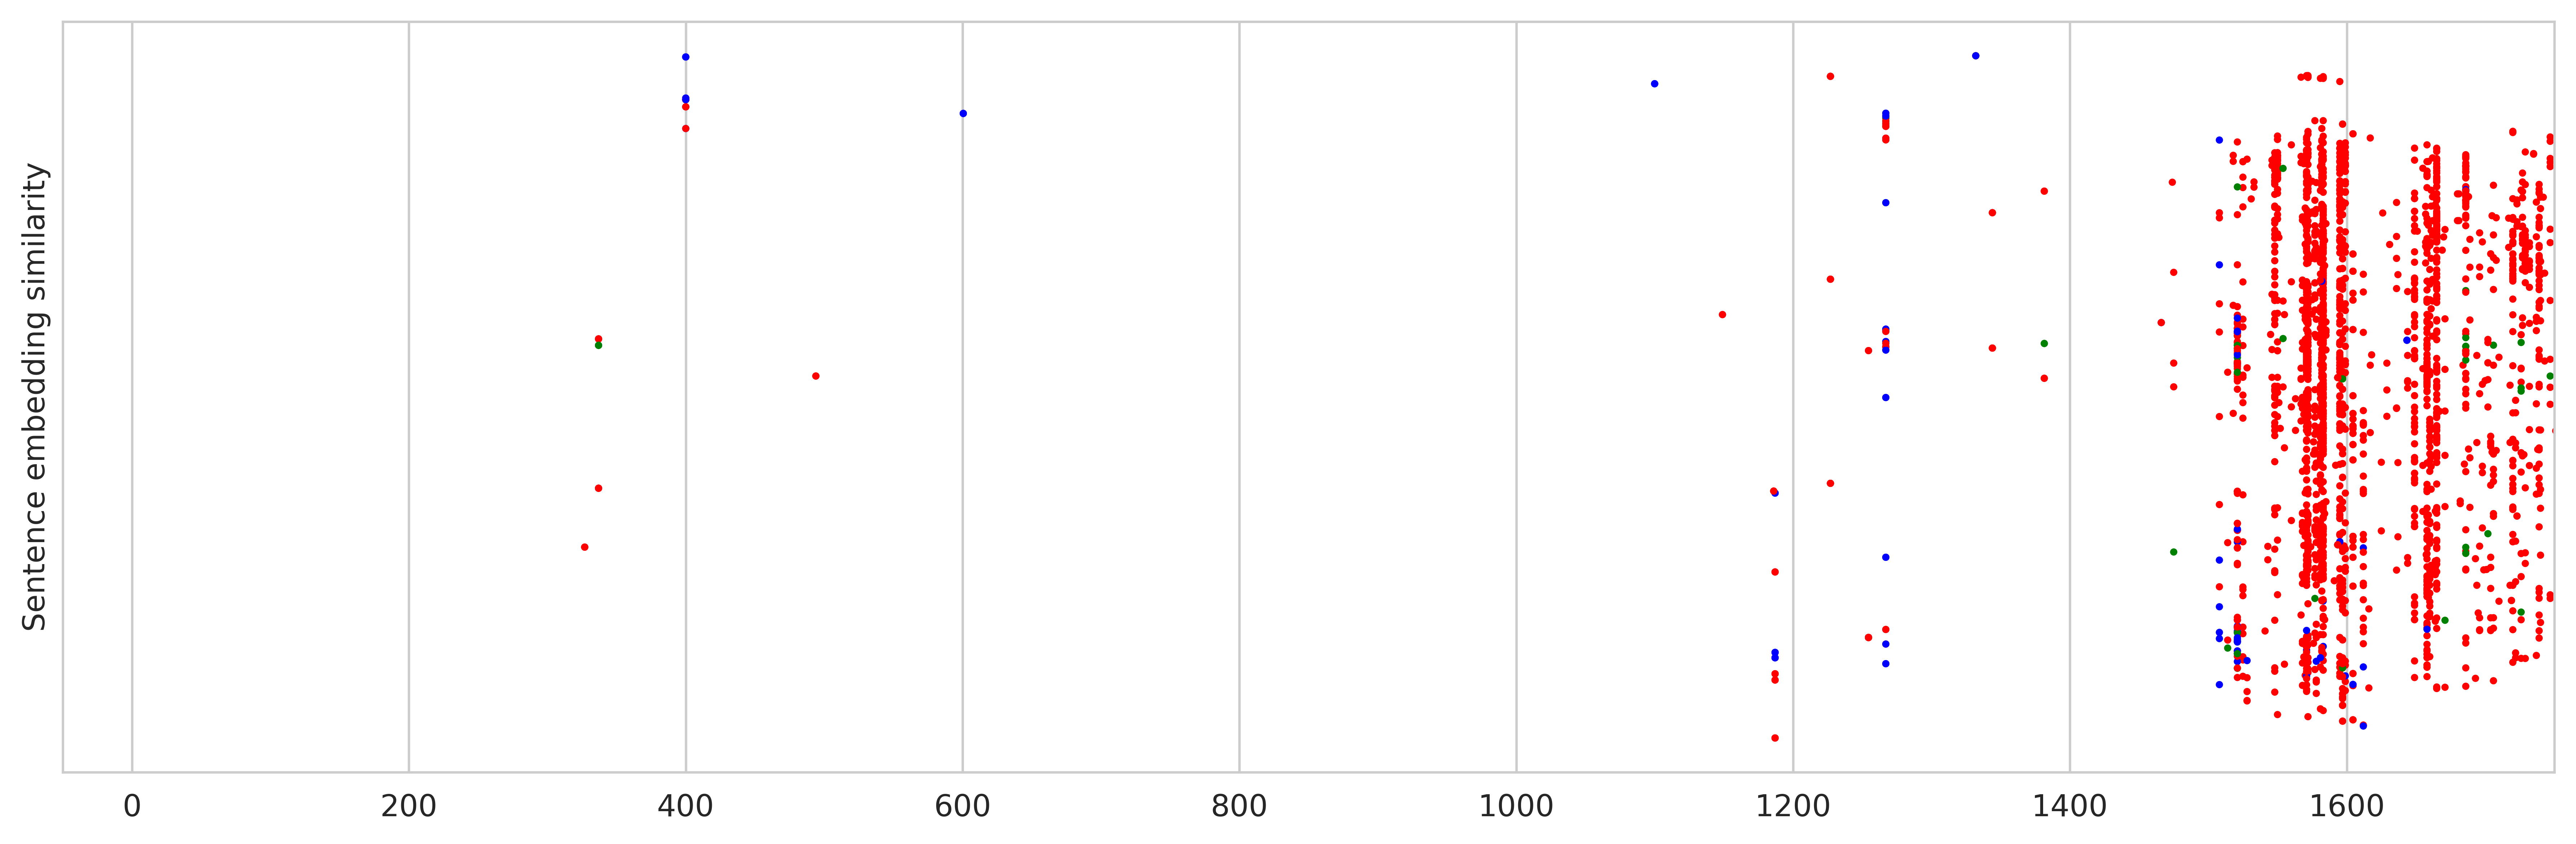

In [215]:
fig, ax = plt.subplots(tight_layout=True, dpi=600, figsize=(12,4))
ax.scatter(x=years, y=embeddings_tsne, c=colors, s=2)# You may want to adjust the size depending on your similarity matrix
ax.set_yticks([])
ax.set_ylabel("Sentence embedding similarity")
ax.set_xlim(-50, 1750)

In [216]:
hover_text = tar_sents_df.apply(
    lambda row: f'{row["sentence"]} ({row["author"] if row["author"] else "Unknown"}, {row["year"] if row["year"] else "Unknown"})',
    axis=1
)


In [217]:
xs = years
ys = [np.round(n, 2) for n in embeddings_tsne2d[:, 0]]
zs = [np.round(n, 2) for n in embeddings_tsne2d[:, 1]]

In [218]:
title = "Sentences with 'mercurius' (N={})".format(len(tar_sents_df))
fig = go.Figure(data=go.Scatter3d(
    x=xs,
    y=ys,
    z=zs,
    mode='markers',
    marker=dict(
        size=5,
        color=colors,
        opacity=0.8
    ),
    text=hover_text,  # use mapped hover text
    hoverinfo='text',  # ensure only the text field is displayed on hover
))

fig.update_layout(
    title=title,
    scene=dict(
        xaxis=dict(title='year', showbackground=False, showgrid=True, showline=True), #showline=True, showticklabels=True, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        #xaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        yaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        zaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        bgcolor='rgba(255,255,255,0)'
    ),
    paper_bgcolor='rgba(255,255,255,255)',  # set the color of the area around the axes
    plot_bgcolor='rgba(255,255,255,255)',  # set the color of the entire chart
    autosize=False,
    width=1000,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0)
)


In [219]:
pio.write_html(fig, file="../figures/mercurius-diachronic.html")

In [112]:
#html_code = pio.to_html(fig, include_plotlyjs='cdn')
#pyperclip.copy(html_code)

In [65]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=0).fit(target_embeddings)
labels = kmeans.labels_
cluster_colors = {0: "#1f77b4",  # muted blue
                  1: "#ff7f0e",  # safety orange
                  2: "#2ca02c",  # cooked asparagus green
                  3: "#d62728",  # brick red
                  4: "#9467bd"}
# colors = [cluster_colors[l] for l in labels]

In [66]:
tsne = TSNE(n_components=3, perplexity=30)
embeddings_tsne = tsne.fit_transform(np.vstack(target_vectors))

In [67]:
xs = embeddings_tsne[:, 0]
ys = embeddings_tsne[:, 1]
zs = embeddings_tsne[:, 2]

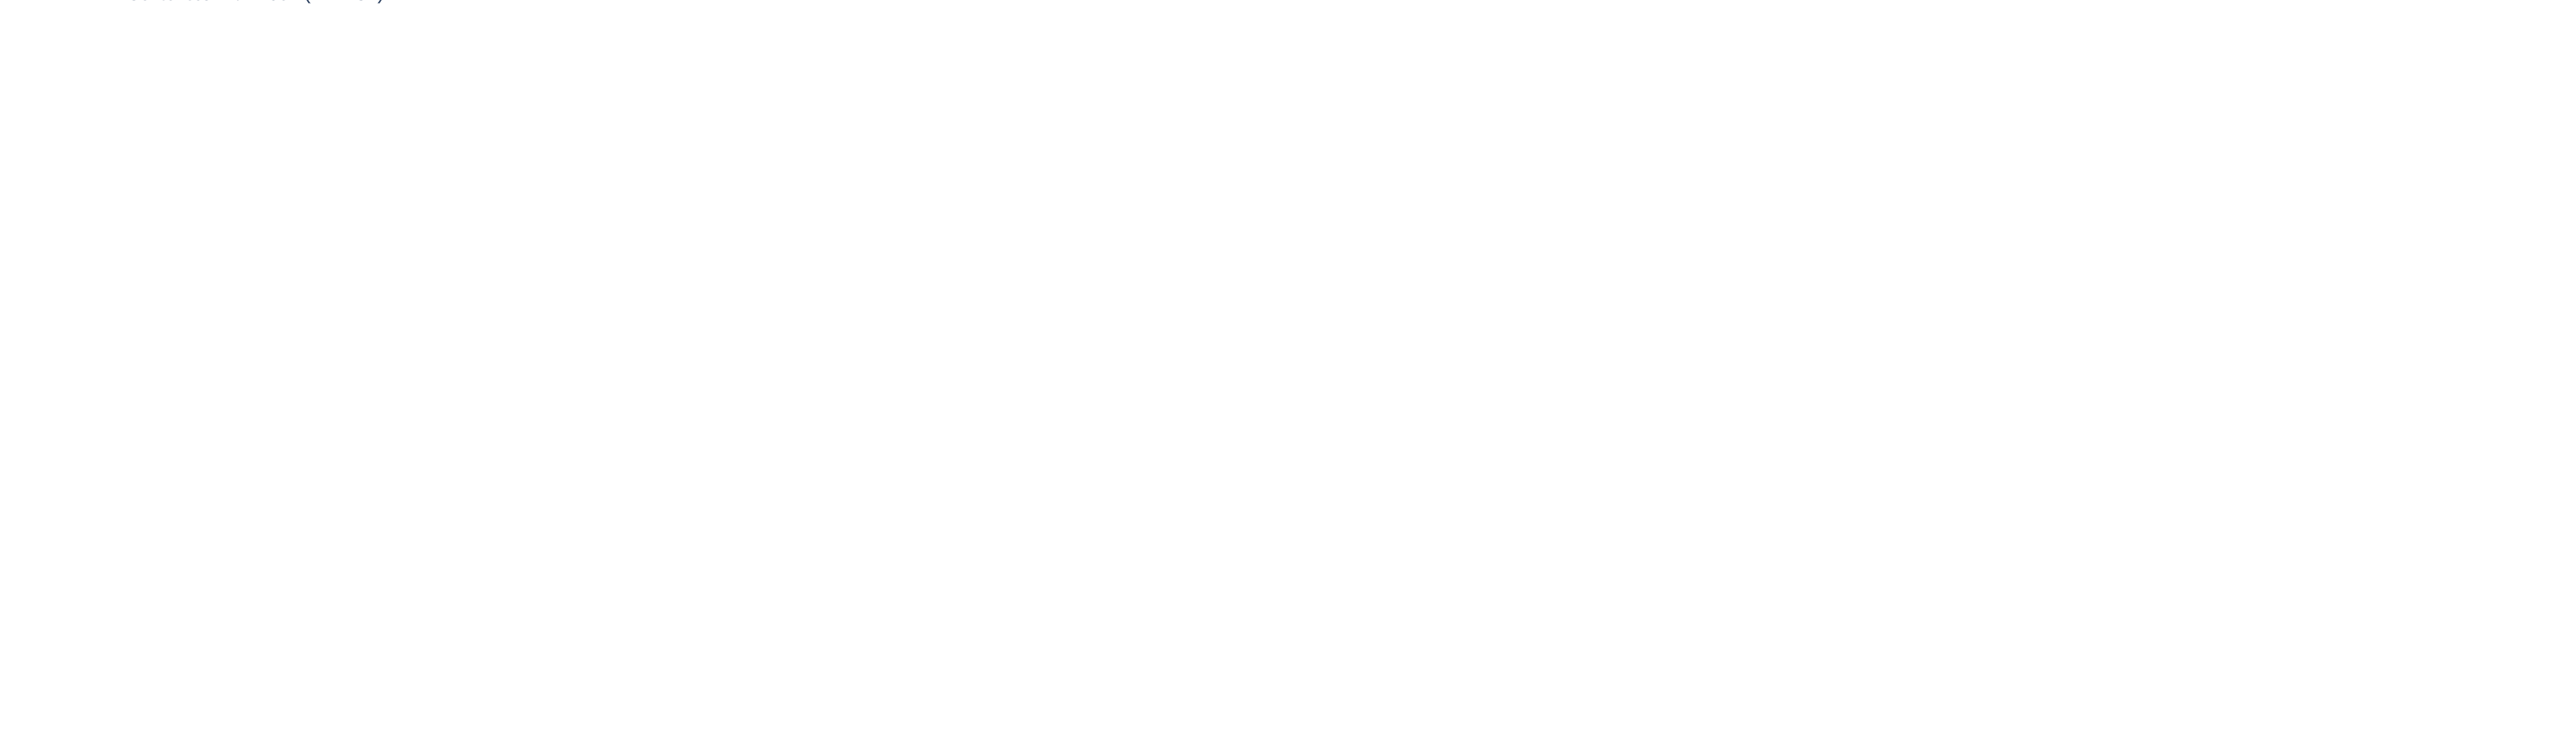

In [68]:
title = "Sentences with 'liber' (N={})".format(len(sentences))
fig = go.Figure(data=go.Scatter3d(
    x=xs,
    y=ys,
    z=zs,
    mode='markers',
    marker=dict(
        size=5,
        color=colors,
        opacity=0.8
    ),
    text=hover_text,  # use mapped hover text
    hoverinfo='text',  # ensure only the text field is displayed on hover
))

fig.update_layout(
    title=title,
    scene=dict(
        xaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        yaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        zaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        bgcolor='rgba(255,255,255,0)'
    ),
    paper_bgcolor='rgba(255,255,255,255)',  # set the color of the area around the axes
    plot_bgcolor='rgba(255,255,255,255)',  # set the color of the entire chart
    autosize=False,
    width=1000,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0)
)


In [69]:
pio.write_html(fig, file="../figures/liber-sample.html")

In [70]:
#html_code = pio.to_html(fig, include_plotlyjs='cdn')
#pyperclip.copy(html_code)

In [71]:
len(sents_dfs)

2154

### Classification

In [89]:
# load back the anotated data, directly from gspread sheet
sents_meta_anot = get_as_dataframe(liber_naturae_gs.worksheet("sents_meta_df_v1"))
sents_meta_anot.head(5)

,0,1,2,author,year,Metaphor,Cross-reference,Internal reference,Reference to Pliny the Elder - Naturalis historia,Reference to another author's work,Metaphor in natural magic (chiromancy),Metaphor in astrology/astronomy,Metaphor in natural philosophy/physics,Metaphor in medicine or botany,"Metaphor in (philosophical) theology, encyclopaedism, or bibliography",Incorrect lemma
0,637738,214,Argumentum affers quam obrem alteram ab altera...,Leoniceno,1509.0,False,True,False,True,False,False,False,False,False,False,False
1,841475,11568,Colligit Aristoteles libro naturalium tertio s...,Pio,1514.0,False,True,False,False,Aristotle,False,False,False,False,False,False
2,841475,31362,Sanctaria scrinia & secretiora repositoria Pli...,Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False
3,841475,24338,lege Senecam libro naturaliu primo.,Pio,1514.0,False,True,False,False,Seneca,False,False,False,False,False,False
4,841475,55017,"phantida foeminae, quam multa composuit, nomen...",Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False


In [90]:
# so how many metaphors do we have?
sents_meta_anot["Metaphor"].sum()

62

In [100]:
class_data = sents_dfs[:154]  #+ random.sample(sents_dfs[154:], 346)

In [101]:
class_data[0][4]

,spacy_tokens,spacy_lemma,spacy_pos,spacy_position,bert_tokens,bert_tok_emb,bert_avg_emb,bert_avg_decontext,cos_sim
0,omnes,omnis,DET,"(0, 5)",[omnes_],"[[-0.2267545, 0.03534043, -0.57197773, -0.8987...","[-0.22675450146198273, 0.03534042835235596, -0...","[-0.012650368735194206, 0.03062467835843563, -...",0.016544
1,hi,hic,DET,"(6, 8)",[hi],"[[0.065882646, 0.15884511, -0.29995036, -0.766...","[0.06588264554738998, 0.15884511172771454, -0....","[0.05322127416729927, -0.01336828712373972, -0...",0.089138
2,cum,cum,ADP,"(9, 12)",[cum],"[[-0.078728326, 0.013177161, -0.32417047, -1.1...","[-0.0787283256649971, 0.013177161104977131, -0...","[0.05187046155333519, -0.02129324898123741, 0....",0.014447
3,lanne,,NOUN,"(13, 18)","[lan, ne_]","[[-0.5393002, 0.017649591, -0.66978925, -1.107...","[-0.47358882427215576, -0.15611495077610016, -...","[0.000102214515209198, 0.019755538552999496, -...",0.086808
4,&,&,PUNCT,"(19, 20)",[&],"[[-0.098285615, 0.25577477, -0.37196028, -0.89...","[-0.09828561544418335, 0.25577476620674133, -0...","[0.053975727409124374, 0.02921023964881897, -0...",0.005627
5,Mambre,,PROPN,"(21, 27)","[mam, bre_]","[[-0.11211276, 0.24862047, -0.40294325, -1.211...","[-0.29018062353134155, 0.20940619707107544, -0...","[-0.005745686125010252, -0.022986212745308876,...",0.003742
6,et,et,CCONJ,"(28, 30)",[et],"[[-0.18621594, 0.017778393, -0.23182139, -1.04...","[-0.18621593713760376, 0.017778392881155014, -...","[0.023676078766584396, -0.015391281805932522, ...",0.065091
7,Simone,Simo,PROPN,"(31, 37)","[simo, ne_]","[[-0.5339989, 0.17992054, -0.07132285, -0.8835...","[-0.5432291626930237, -0.11695485562086105, -0...","[0.027885613963007927, -0.0015635404270142317,...",0.022789
8,mago,magus,NOUN,"(38, 42)",[mago],"[[-0.103658386, 0.119519696, -0.38165584, -0.6...","[-0.10365838557481766, 0.11951969563961029, -0...","[0.09494044631719589, -0.025257257744669914, 0...",0.058823
9,aeternis,aeternus,ADJ,"(43, 51)","[aeterni, s_]","[[-0.5825693, 0.15036915, -0.29319075, -1.0211...","[-0.5024323463439941, -0.09176509827375412, -0...","[-0.01861829124391079, 0.029625626280903816, -...",0.126318


In [102]:
target = "liber"
target_vectors = []
for sent_data in class_data:
    df = sent_data[4]
    target_row = df.loc[df["spacy_lemma"] == target].iloc[0]
    target_vectors.append(target_row['bert_avg_emb'])

In [104]:
### Y = 154 * [1] + 346 * [0] 

y_anotated = sents_meta_anot["Metaphor"].apply(lambda x: 1 if x else 0).tolist()
Y = y_anotated # + 346 * [0] 
Y

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0]

In [105]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [107]:
len(target_vectors)

154

In [108]:
len(Y)

154

In [109]:
X_trainval, X_test, Y_trainval, Y_test = train_test_split(target_vectors, Y, test_size=0.2, random_state=42, stratify=Y)

In [110]:
# Split train into train-val
X_train, X_val, Y_train, Y_val = train_test_split(X_trainval, Y_trainval, test_size=0.2, random_state=42,
                                                  stratify=Y_trainval)

In [113]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

LogisticRegression(max_iter=1000)

In [114]:
# Predict probabilities
Y_pred_proba = model.predict_proba(X_val)
Y_pred_proba

array([[0.49584108, 0.50415892],
       [0.44774062, 0.55225938],
       [0.97469671, 0.02530329],
       [0.01558113, 0.98441887],
       [0.28855919, 0.71144081],
       [0.58499528, 0.41500472],
       [0.91452307, 0.08547693],
       [0.38044211, 0.61955789],
       [0.18917185, 0.81082815],
       [0.07154985, 0.92845015],
       [0.26157172, 0.73842828],
       [0.92607911, 0.07392089],
       [0.85027093, 0.14972907],
       [0.05408494, 0.94591506],
       [0.92632414, 0.07367586],
       [0.72466083, 0.27533917],
       [0.99055796, 0.00944204],
       [0.4208823 , 0.5791177 ],
       [0.11520987, 0.88479013],
       [0.95689953, 0.04310047],
       [0.07463577, 0.92536423],
       [0.22153638, 0.77846362],
       [0.55196967, 0.44803033],
       [0.63374265, 0.36625735],
       [0.11348027, 0.88651973]])

In [ ]:
# Predict probabilities
Y_pred_proba = model.predict_proba(X_val)

# Get probabilities of the positive class (assuming binary classification)
Y_pred_proba_positive_class = Y_pred_proba[:, 1]

In [111]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

Y_pred = model.predict(X_val)

print('Validation Accuracy: ', accuracy_score(Y_val, Y_pred))
print('\nClassification Report:\n', classification_report(Y_val, Y_pred))

Validation Accuracy:  0.6

Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.53      0.62        15
           1       0.50      0.70      0.58        10

    accuracy                           0.60        25
   macro avg       0.61      0.62      0.60        25
weighted avg       0.64      0.60      0.60        25



In [112]:
Y_pred

array([1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 0, 1])

In [127]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

Y_pred = model.predict(X_val)

print('Validation Accuracy: ', accuracy_score(Y_val, Y_pred))
print('\nClassification Report:\n', classification_report(Y_val, Y_pred))

Validation Accuracy:  0.9125

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.91      0.93        55
           1       0.82      0.92      0.87        25

    accuracy                           0.91        80
   macro avg       0.89      0.91      0.90        80
weighted avg       0.92      0.91      0.91        80



[Text(0, 0.5, 'liber\n(random)'), Text(0, 1.5, 'liber\nnaturae')]

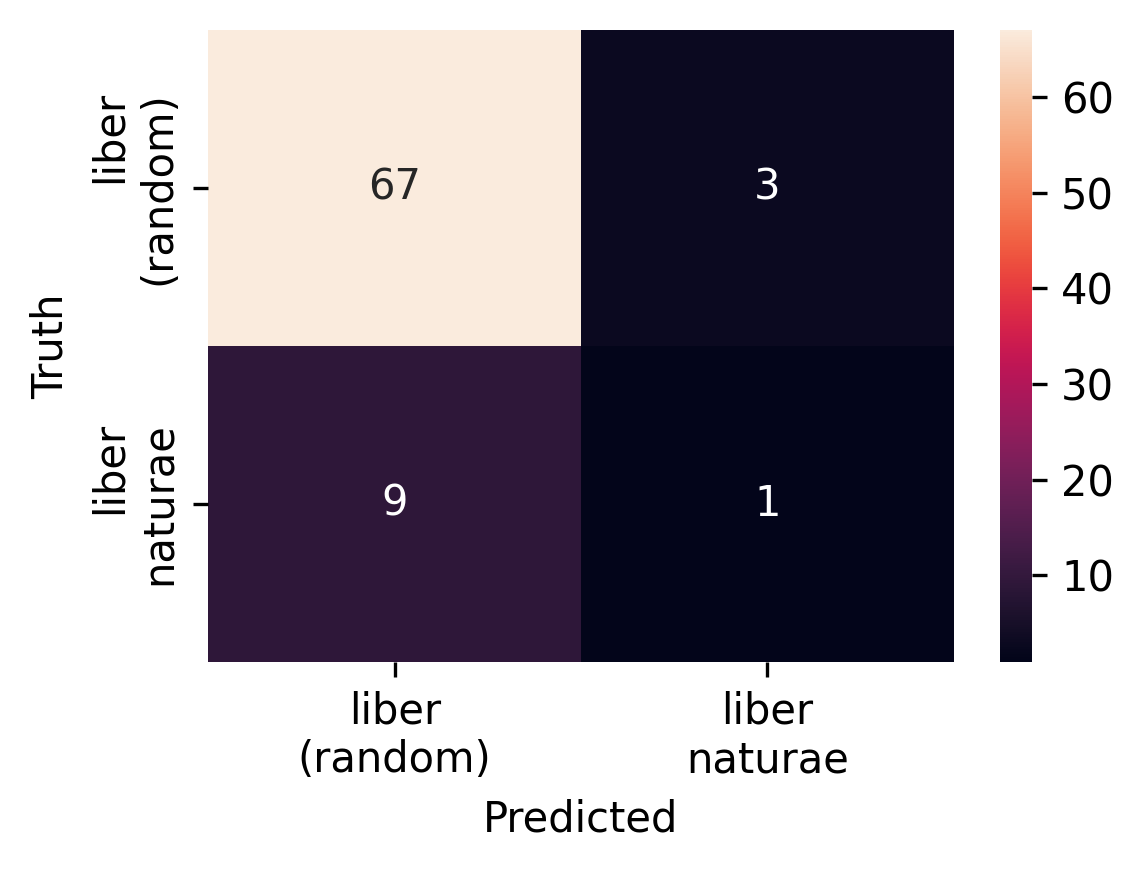

In [99]:
cm = confusion_matrix(Y_val, Y_pred)

fig, ax = plt.subplots(tight_layout=True, dpi=300, figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Truth')
ax.set_xticklabels(["liber\n(random)", "liber\nnaturae"])
ax.set_yticklabels(["liber\n(random)", "liber\nnaturae"])


[Text(0, 0.5, 'liber\n(random)'), Text(0, 1.5, 'liber\nnaturae')]

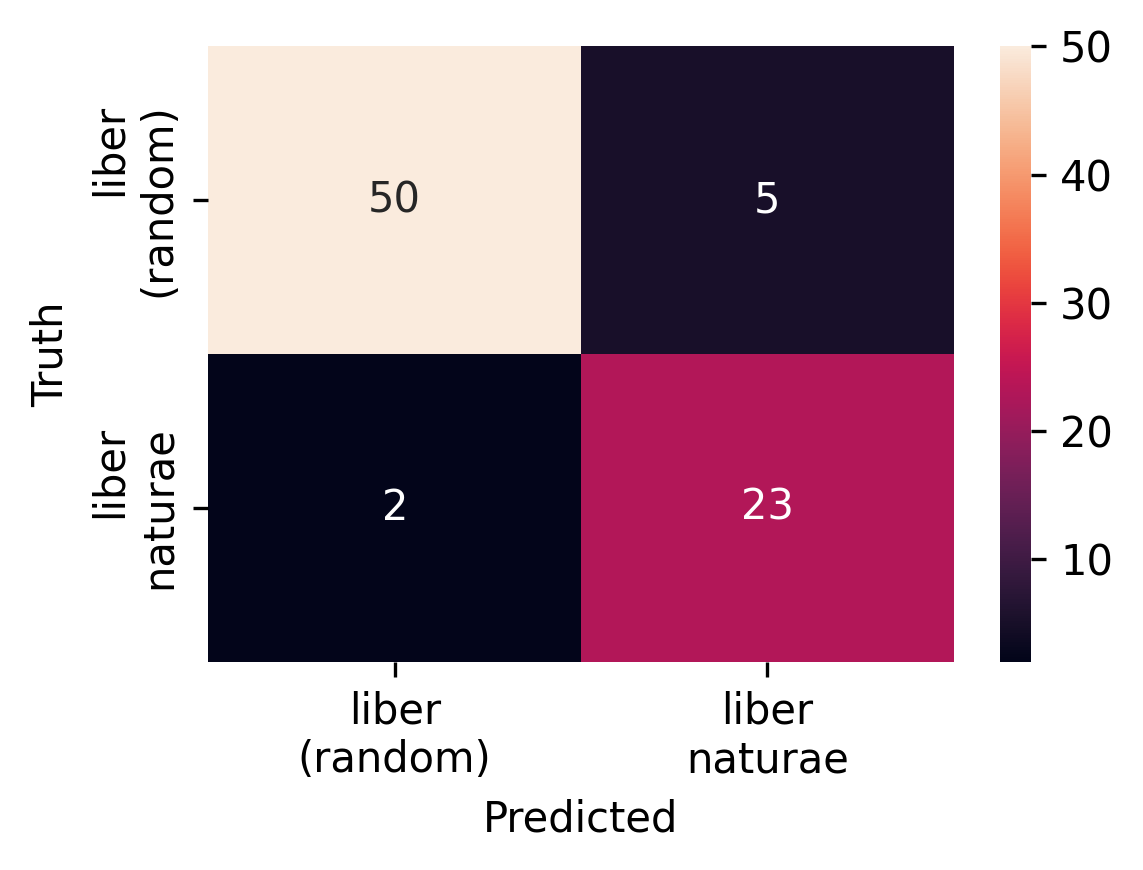

In [128]:
cm = confusion_matrix(Y_val, Y_pred)

fig, ax = plt.subplots(tight_layout=True, dpi=300, figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Truth')
ax.set_xticklabels(["liber\n(random)", "liber\nnaturae"])
ax.set_yticklabels(["liber\n(random)", "liber\nnaturae"])


In [129]:
fig.savefig("../figures/liber-confussion-matrix_v1.png")

### Loading back the annotated data

In [38]:
# load back the anotated data, directly from gspread sheet
sents_meta_anot = get_as_dataframe(liber_naturae_gs.worksheet("sents_meta_df_v1"))

In [39]:
sents_meta_anot.head(5)

,0,1,2,author,year,Metaphor,Cross-reference,Internal reference,Reference to Pliny the Elder - Naturalis historia,Reference to another author's work,Metaphor in natural magic (chiromancy),Metaphor in astrology/astronomy,Metaphor in natural philosophy/physics,Metaphor in medicine or botany,"Metaphor in (philosophical) theology, encyclopaedism, or bibliography",Incorrect lemma
0,637738,214,Argumentum affers quam obrem alteram ab altera...,Leoniceno,1509.0,False,True,False,True,False,False,False,False,False,False,False
1,841475,11568,Colligit Aristoteles libro naturalium tertio s...,Pio,1514.0,False,True,False,False,Aristotle,False,False,False,False,False,False
2,841475,31362,Sanctaria scrinia & secretiora repositoria Pli...,Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False
3,841475,24338,lege Senecam libro naturaliu primo.,Pio,1514.0,False,True,False,False,Seneca,False,False,False,False,False,False
4,841475,55017,"phantida foeminae, quam multa composuit, nomen...",Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False


In [41]:
len(sents_meta_anot)

154

In [40]:
# so how many metaphors do we have?
sents_meta_anot["Metaphor"].sum()

62